# Problem 6: A shifted proposal and the Hastings correction

Use the Gaussian target from Problem 4a:
$$\mu=(2,2),\qquad V=\begin{pmatrix}2&1.2\\1.2&2\end{pmatrix},\qquad
\ell(z)=-\tfrac12(z-\mu)^T V^{-1}(z-\mu).$$
In two dimensions, interpret the proposed shift of $x+2$ as adding 2 to **each** coordinate. Compare the usual proposal, a shifted proposal with the old acceptance rule, and the shifted proposal with the correct Hastings rule.

## Why center the proposal on the current state?

Our previous Gaussian proposals were centered on the current state, so a displacement and its reverse were equally likely: $q(z'\mid z)=q(z\mid z')$. That symmetry justified dropping the proposal terms from the acceptance ratio. Centering also keeps proposals local.

Centering is **not required** by Metropolis–Hastings. An off-center proposal is valid if its forward and reverse densities appear in the acceptance rule. Conversely, centering alone does not guarantee symmetry for every possible proposal family; the Gaussian random walks used here have that property.

Now let $d=(2,2)$ and propose
$$z'=z+d+\epsilon,\qquad \epsilon\sim\mathcal N_2(0,I).$$
Writing $\Delta=z'-z$, the log proposal densities, up to a common constant, are
$$\log q(z'\mid z)=-\tfrac12\|\Delta-d\|^2,\qquad
\log q(z\mid z')=-\tfrac12\|\Delta+d\|^2.$$
Therefore
$$\log\frac{q(z\mid z')}{q(z'\mid z)}
=-\tfrac12\|\Delta+d\|^2+\tfrac12\|\Delta-d\|^2=-2d^T\Delta.$$
The corrected log acceptance ratio is
$$\ell(z')-\ell(z)-2d^T(z'-z).$$
The code accepts when $\log u$ is below the minimum of 0 and this expression. Setting $d=0$ recovers the old symmetric rule.

## Predicting what goes wrong

If we ignore the proposal ratio, the shifted chain targets a tilted density
$$\widetilde p(z)\propto p(z)\exp(2d^Tz),$$
rather than $p(z)$. To check this, insert $\widetilde p$ into the full Hastings ratio: its extra factor $\exp(2d^T\Delta)$ cancels the reverse/forward proposal factor $\exp(-2d^T\Delta)$, leaving precisely the incorrect target-only rule.

Completing the square shows that this tilted density is Gaussian with covariance $V$ and mean
$$\widetilde\mu=\mu+2Vd=(14.8,14.8).$$
Thus the shift produces a systematic error, not just slower convergence. With the correction, the target mean returns to $(2,2)$, but the proposal remains inefficient: it strongly favors positive moves, whose reverse proposals are rare.

All runs start at $(0,0)$ and reset the seed to 42. The symmetric baseline uses 50,000 transitions; the shifted runs use 1,000,000 each because they reject very frequently. All states after transitions are retained, without burn-in removal. Histograms use all states; scatter plots display every 20th state for the longer runs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

mean = np.array([2.0, 2.0])
V = np.array([[2.0, 1.2], [1.2, 2.0]])
V_inv = np.linalg.inv(V)

def log_p(z):
    d = z - mean
    return -0.5 * d @ V_inv @ d

def sample(shift, corrected, steps):
    rng = np.random.default_rng(42)
    drift = np.full(2, shift)
    z = np.zeros(2)
    log_current = log_p(z)
    chain = np.empty((steps, 2))
    accepted = 0
    for i in range(steps):
        proposal = z + drift + rng.normal(size=2)
        log_proposal = log_p(proposal)
        log_ratio = log_proposal - log_current
        if corrected:
            log_ratio -= 2 * drift @ (proposal - z)
        if np.log(rng.random()) < min(0.0, log_ratio):
            z, log_current = proposal, log_proposal
            accepted += 1
        chain[i] = z
    return chain, accepted / steps

In [2]:
settings = [("Symmetric baseline", 0, False, 50_000),
            ("Shifted, incorrect rule", 2, False, 1_000_000),
            ("Shifted, Hastings correction", 2, True, 1_000_000)]
runs = [(name, *sample(shift, corrected, steps))
        for name, shift, corrected, steps in settings]
wrong_mean = mean + 2 * V @ np.array([2.0, 2.0])
for name, chain, acceptance in runs:
    print(f"{name}: {len(chain):,} states, acceptance={acceptance:.4f}")
    print("Mean:", chain.mean(0).round(4))
    print("Covariance:\n", np.cov(chain, rowvar=False, ddof=0).round(4))

Symmetric baseline: 50,000 states, acceptance=0.6077
Mean: [1.9816 1.9634]
Covariance:
 [[2.0149 1.1978]
 [1.1978 1.9847]]
Shifted, incorrect rule: 1,000,000 states, acceptance=0.0040
Mean: [14.8438 14.8596]
Covariance:
 [[2.1879 1.3985]
 [1.3985 2.2567]]
Shifted, Hastings correction: 1,000,000 states, acceptance=0.0040
Mean: [2.0721 2.0865]
Covariance:
 [[2.0921 1.2911]
 [1.2911 2.0911]]


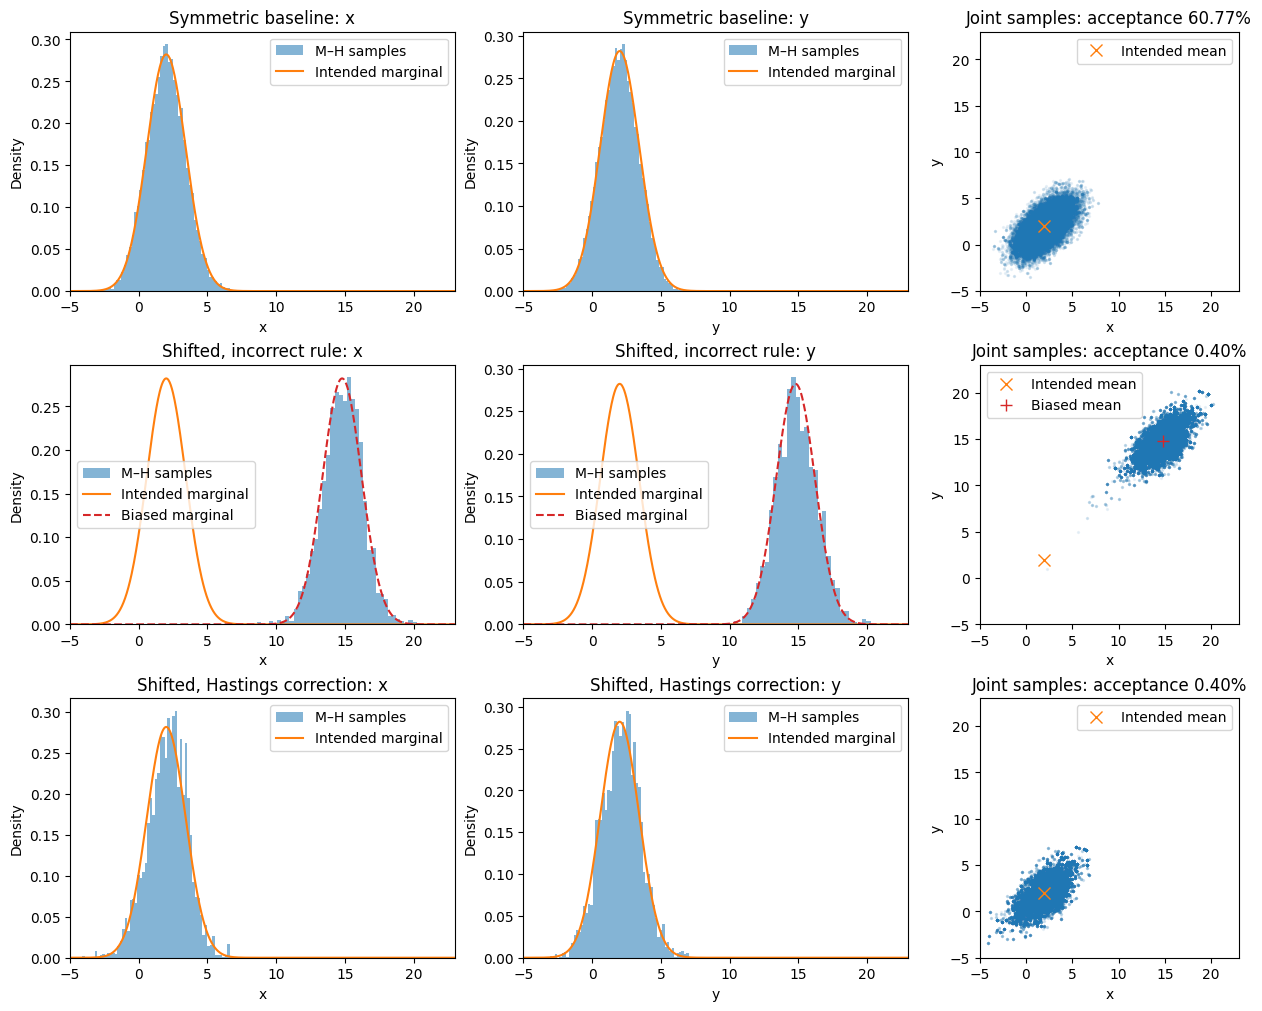

In [3]:
grid = np.linspace(-5, 23, 700)
density = np.exp(-(grid - 2) ** 2 / 4) / np.sqrt(4 * np.pi)
wrong_density = np.exp(-(grid - wrong_mean[0]) ** 2 / 4) / np.sqrt(4 * np.pi)
fig, axes = plt.subplots(3, 3, figsize=(13, 10), constrained_layout=True)
for row, (name, chain, acceptance) in enumerate(runs):
    for j, coordinate in enumerate(("x", "y")):
        ax = axes[row, j]
        ax.hist(chain[:, j], bins=60, density=True, alpha=0.55, label="M–H samples")
        ax.plot(grid, density, color="tab:orange", label="Intended marginal")
        if row == 1:
            ax.plot(grid, wrong_density, "--", color="tab:red", label="Biased marginal")
        ax.set(title=f"{name}: {coordinate}", xlabel=coordinate, ylabel="Density", xlim=(-5, 23))
        ax.legend()
    ax = axes[row, 2]
    shown = chain[::max(1, len(chain) // 50_000)]
    ax.scatter(shown[:, 0], shown[:, 1], s=2, alpha=0.08, rasterized=True)
    ax.plot(*mean, "x", color="tab:orange", markersize=9, label="Intended mean")
    if row == 1:
        ax.plot(*wrong_mean, "+", color="tab:red", markersize=9, label="Biased mean")
    ax.set(title=f"Joint samples: acceptance {acceptance:.2%}", xlabel="x", ylabel="y",
           xlim=(-5, 23), ylim=(-5, 23), aspect="equal")
    ax.legend()
plt.show()

## What can we conclude?

The symmetric baseline samples the intended Gaussian. Ignoring the proposal ratio shifts the sampled cloud toward $(14.8,14.8)$; running longer cannot repair that incorrect stationary distribution. Including the Hastings correction restores the intended target.

The correction fixes the stationary distribution, **not the proposal's efficiency**. Even with a million transitions, very few shifted moves are accepted and repeated states are common. Finite-run moments and histograms can remain noticeably noisier than the baseline. The extra transitions here help demonstrate the correction; they do not turn this into a good proposal or prove convergence.

A proposal centered on the current state was a convenient way to obtain a symmetric, local random walk. The general lesson is to retain the forward/reverse proposal ratio whenever that symmetry is absent.